# KHAI PHÁ DỮ LIỆU — LAB 1 · Phần 2 · Bài 5b (Trang 45): Luật kết hợp — France, min_sup = 7%, min_conf = 70%

            | | |
            |---|---|
            | **Sinh viên** | Phan Quốc Thắng |
            | **MSSV** | 6451071073 |
            | **Lớp** | CNTT-K64 |
            | **GVHD** | ThS. Nguyễn Thiện Dương |

            Thực hiện lại bài tập lập trình ở phần hướng dẫn chung (Online Retail) với nước **France**,
**min_sup = 7%** và **min_conf = 70%**.

## Khai báo thông tin sinh viên & thư viện

In [1]:
HO_TEN = "Phan Quốc Thắng"
MSSV = "6451071073"
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")
SEED = int(MSSV[-4:])          # seed lấy từ MSSV để kết quả tái lập được
rng = np.random.default_rng(SEED)
DATA = "../data/"

from scipy.sparse import coo_matrix
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

COUNTRY, MIN_SUP, MIN_CONF = "France", 0.07, 0.7

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


## Câu 1: Đọc dữ liệu và làm sạch (Description, InvoiceNo, hoá đơn tín dụng)

In [2]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
df = pd.read_excel(DATA + "Online Retail.xlsx")
print("Kích thước ban đầu:", df.shape)
df["Description"] = df["Description"].str.strip()
df = df.dropna(axis=0, subset=["InvoiceNo"])
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df = df[~df["InvoiceNo"].str.contains("C")]
print("Kích thước sau làm sạch:", df.shape)
print(f"Số dòng của {COUNTRY}:", (df["Country"] == COUNTRY).sum())
display(df[df["Country"] == COUNTRY].head())

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


Kích thước ban đầu: (541909, 8)


Kích thước sau làm sạch: (532621, 8)
Số dòng của France: 8408


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
26,536370,22728,ALARM CLOCK BAKELIKE PINK,24,2010-12-01 08:45:00,3.75,12583.0,France
27,536370,22727,ALARM CLOCK BAKELIKE RED,24,2010-12-01 08:45:00,3.75,12583.0,France
28,536370,22726,ALARM CLOCK BAKELIKE GREEN,12,2010-12-01 08:45:00,3.75,12583.0,France
29,536370,21724,PANDA AND BUNNIES STICKER SHEET,12,2010-12-01 08:45:00,0.85,12583.0,France
30,536370,21883,STARS GIFT TAPE,24,2010-12-01 08:45:00,0.65,12583.0,France


**Nhận xét:**

- Sau làm sạch, **France có 8 408 dòng**. Hoá đơn đầu tiên đã cho thấy khách Pháp hay mua đồng hồ ALARM CLOCK BAKELIKE nhiều màu cùng lúc.

## Câu 2: Lọc hoá đơn theo quốc gia, gom nhóm và chuyển về one-hot encoding, xoá POSTAGE

In [3]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
basket = (df[df["Country"] == COUNTRY]
          .groupby(["InvoiceNo", "Description"])["Quantity"].sum()
          .unstack().reset_index().fillna(0).set_index("InvoiceNo"))
print("Hot encoding (số lượng) — kích thước:", basket.shape)
display(basket.iloc[:5, :8])

def encode_units(x):
    return 1 if x > 0 else 0
basket_sets = basket.map(encode_units).astype(bool)
basket_sets = basket_sets.drop(columns=["POSTAGE"], errors="ignore")
print("One-hot sau khi xoá POSTAGE — kích thước:", basket_sets.shape)
display(basket_sets.iloc[:5, :8].astype(int))

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
Hot encoding (số lượng) — kích thước: (392, 1563)


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 EGG HOUSE PAINTED WOOD,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY
InvoiceNo,,,,,,,,
536370,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536852,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536974,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
537065,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
537463,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


One-hot sau khi xoá POSTAGE — kích thước: (392, 1562)


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 EGG HOUSE PAINTED WOOD,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY
InvoiceNo,,,,,,,,
536370,0,0,0,0,0,0,0,0
536852,0,0,0,0,0,0,0,0
536974,0,0,0,0,0,0,0,0
537065,0,0,0,0,0,0,0,0
537463,0,0,0,0,0,0,0,0


**Nhận xét:**

- Dữ liệu Pháp gồm **392 hoá đơn × 1 563 mặt hàng**, sau khi xoá POSTAGE còn 1 562 mặt hàng.

## Câu 3: Tìm tập phổ biến bằng Apriori

In [4]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
t0 = time.perf_counter()
frequent_ap = apriori(basket_sets, min_support=MIN_SUP, use_colnames=True)
t_ap = time.perf_counter() - t0
frequent_ap["length"] = frequent_ap["itemsets"].apply(len)
print(f"min_sup = {MIN_SUP:.0%} | Số tập phổ biến: {len(frequent_ap)} | thời gian: {t_ap:.3f} s")
print("Số tập theo độ dài:", frequent_ap["length"].value_counts().sort_index().to_dict())
display(frequent_ap.sort_values("support", ascending=False).head(10))

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
min_sup = 7% | Số tập phổ biến: 51 | thời gian: 0.005 s
Số tập theo độ dài: {1: 40, 2: 10, 3: 1}


,support,itemsets,length
22,0.188776,frozenset({RABBIT NIGHT LIGHT}),1
26,0.181122,frozenset({RED TOADSTOOL LED NIGHT LIGHT}),1
21,0.170918,frozenset({PLASTERS IN TIN WOODLAND ANIMALS}),1
18,0.168367,frozenset({PLASTERS IN TIN CIRCUS PARADE}),1
30,0.158163,frozenset({ROUND SNACK BOXES SET OF4 WOODLAND}),1
11,0.153061,frozenset({LUNCH BAG RED RETROSPOT}),1
14,0.142857,frozenset({LUNCH BOX WITH CUTLERY RETROSPOT}),1
19,0.137755,frozenset({PLASTERS IN TIN SPACEBOY}),1
33,0.137755,frozenset({SET/6 RED SPOTTY PAPER CUPS}),1
24,0.137755,frozenset({RED RETROSPOT MINI CASES}),1


**Nhận xét:**

- Với min_sup = 7% (≥ 28 hoá đơn) có **51 tập phổ biến** gồm 40 tập 1 phần tử, 10 tập 2 phần tử và 1 tập 3 phần tử. Tập 3 phần tử là {SET/20 RED RETROSPOT PAPER NAPKINS, SET/6 RED SPOTTY PAPER CUPS, SET/6 RED SPOTTY PAPER PLATES}.
- Mặt hàng phổ biến nhất là RABBIT NIGHT LIGHT (18.9%) và RED TOADSTOOL LED NIGHT LIGHT (18.1%).

## Câu 4: Tạo luật kết hợp và in ra các luật

In [5]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
rules_ap = association_rules(frequent_ap, metric="confidence", min_threshold=MIN_CONF)
rules_ap["antecedents"] = rules_ap["antecedents"].apply(lambda x: ", ".join(sorted(x)))
rules_ap["consequents"] = rules_ap["consequents"].apply(lambda x: ", ".join(sorted(x)))
rules_ap = rules_ap.sort_values(["confidence", "lift"], ascending=False).reset_index(drop=True)
print(f"min_conf = {MIN_CONF:.0%} | Số luật tìm được: {len(rules_ap)}")
display(rules_ap[["antecedents", "consequents", "support", "confidence", "lift"]].round(4))
for _, r in rules_ap.iterrows():
    print(f"{{{r['antecedents']}}} => {{{r['consequents']}}}  (sup = {r['support']:.4f}, conf = {r['confidence']:.4f}, lift = {r['lift']:.2f})")

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
min_conf = 70% | Số luật tìm được: 20


,antecedents,consequents,support,confidence,lift
0,"SET/20 RED RETROSPOT PAPER NAPKINS, SET/6 RED ...",SET/6 RED SPOTTY PAPER PLATES,0.0995,0.9750,7.6440
1,"SET/20 RED RETROSPOT PAPER NAPKINS, SET/6 RED ...",SET/6 RED SPOTTY PAPER CUPS,0.0995,0.9750,7.0778
2,SET/6 RED SPOTTY PAPER PLATES,SET/6 RED SPOTTY PAPER CUPS,0.1224,0.9600,6.9689
3,SET/6 RED SPOTTY PAPER CUPS,SET/6 RED SPOTTY PAPER PLATES,0.1224,0.8889,6.9689
4,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE GREEN,0.0791,0.8378,8.6430
5,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.0791,0.8158,8.6430
6,"SET/6 RED SPOTTY PAPER CUPS, SET/6 RED SPOTTY ...",SET/20 RED RETROSPOT PAPER NAPKINS,0.0995,0.8125,6.1250
7,SET/6 RED SPOTTY PAPER PLATES,SET/20 RED RETROSPOT PAPER NAPKINS,0.1020,0.8000,6.0308
8,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE PINK,0.0740,0.7838,7.6811
9,SET/6 RED SPOTTY PAPER PLATES,"SET/20 RED RETROSPOT PAPER NAPKINS, SET/6 RED ...",0.0995,0.7800,7.6440


{SET/20 RED RETROSPOT PAPER NAPKINS, SET/6 RED SPOTTY PAPER CUPS} => {SET/6 RED SPOTTY PAPER PLATES}  (sup = 0.0995, conf = 0.9750, lift = 7.64)
{SET/20 RED RETROSPOT PAPER NAPKINS, SET/6 RED SPOTTY PAPER PLATES} => {SET/6 RED SPOTTY PAPER CUPS}  (sup = 0.0995, conf = 0.9750, lift = 7.08)
{SET/6 RED SPOTTY PAPER PLATES} => {SET/6 RED SPOTTY PAPER CUPS}  (sup = 0.1224, conf = 0.9600, lift = 6.97)
{SET/6 RED SPOTTY PAPER CUPS} => {SET/6 RED SPOTTY PAPER PLATES}  (sup = 0.1224, conf = 0.8889, lift = 6.97)
{ALARM CLOCK BAKELIKE RED} => {ALARM CLOCK BAKELIKE GREEN}  (sup = 0.0791, conf = 0.8378, lift = 8.64)
{ALARM CLOCK BAKELIKE GREEN} => {ALARM CLOCK BAKELIKE RED}  (sup = 0.0791, conf = 0.8158, lift = 8.64)
{SET/6 RED SPOTTY PAPER CUPS, SET/6 RED SPOTTY PAPER PLATES} => {SET/20 RED RETROSPOT PAPER NAPKINS}  (sup = 0.0995, conf = 0.8125, lift = 6.12)
{SET/6 RED SPOTTY PAPER PLATES} => {SET/20 RED RETROSPOT PAPER NAPKINS}  (sup = 0.1020, conf = 0.8000, lift = 6.03)
{ALARM CLOCK BAKELIKE RED

**Nhận xét:**

- Ngưỡng min_conf = 70% khá chặt nhưng vẫn có **20 luật**. Luật mạnh nhất là {NAPKINS, PAPER CUPS} ⇒ {PAPER PLATES} với conf 97.5%, lift 7.64: gần như ai mua khăn giấy và cốc giấy đỏ đều mua thêm đĩa giấy đỏ.
- Các luật tập trung vào 2 nhóm: **bộ đồ tiệc giấy màu đỏ** (cốc – đĩa – khăn, gồm cả luật 3 phần tử) và **đồng hồ ALARM CLOCK BAKELIKE** 3 màu đỏ/xanh/hồng (conf 72.5 – 83.8%, lift 7.5 – 8.6).
- Gợi ý kinh doanh: bán trọn bộ "party set" và bộ đồng hồ nhiều màu cho thị trường Pháp.

## Câu 5: Biểu diễn độ tin cậy, độ hỗ trợ của tập luật lên đồ thị phân tán

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


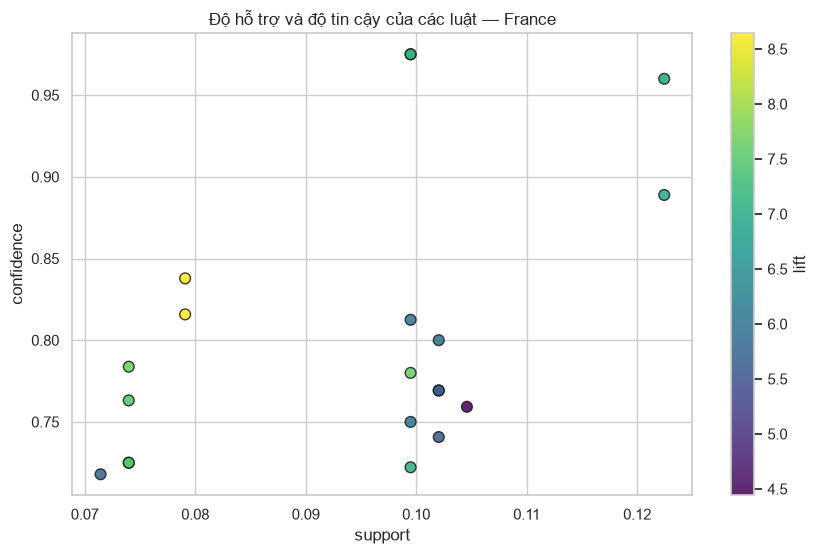

In [6]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(rules_ap["support"], rules_ap["confidence"], c=rules_ap["lift"], cmap="viridis",
                s=60, alpha=0.85, edgecolors="k")
plt.colorbar(sc, label="lift")
ax.set_title(f"Độ hỗ trợ và độ tin cậy của các luật — {COUNTRY}"); ax.set_xlabel("support"); ax.set_ylabel("confidence")
plt.show()

**Nhận xét:**

- 20 luật có support 0.071 – 0.122 và confidence 0.72 – 0.975. Các điểm tạo thành cụm rõ: cụm bộ đồ tiệc giấy (support khoảng 0.10 – 0.12, lift cao 5.6 – 7.6) và cụm đồng hồ (support khoảng 0.074 – 0.079, lift cao nhất khoảng 8.6).
- Confidence cao một phần vì ngưỡng 70% đã loại các luật yếu, nên mọi luật còn lại đều có lift > 4, tức tương quan dương mạnh.

## Câu 6: Tìm tập phổ biến và luật kết hợp bằng FP-Growth và so sánh với Apriori

In [7]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
t0 = time.perf_counter()
frequent_fp = fpgrowth(basket_sets, min_support=MIN_SUP, use_colnames=True)
t_fp = time.perf_counter() - t0
rules_fp = association_rules(frequent_fp, metric="confidence", min_threshold=MIN_CONF)
rules_fp["antecedents"] = rules_fp["antecedents"].apply(lambda x: ", ".join(sorted(x)))
rules_fp["consequents"] = rules_fp["consequents"].apply(lambda x: ", ".join(sorted(x)))
display(rules_fp.sort_values(["confidence", "lift"], ascending=False)[["antecedents", "consequents", "support", "confidence", "lift"]].round(4).head(10).reset_index(drop=True))
same_items = set(frequent_ap["itemsets"]) == set(frequent_fp["itemsets"])
same_rules = set(zip(rules_ap.antecedents, rules_ap.consequents)) == set(zip(rules_fp.antecedents, rules_fp.consequents))
display(pd.DataFrame({"Apriori": [len(frequent_ap), len(rules_ap), round(t_ap, 3)],
                      "FP-Growth": [len(frequent_fp), len(rules_fp), round(t_fp, 3)]},
                     index=["Số tập phổ biến", "Số luật", "Thời gian tìm tập phổ biến (s)"]))
print("Tập phổ biến giống nhau:", same_items, "| Tập luật giống nhau:", same_rules)

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


,antecedents,consequents,support,confidence,lift
0,"SET/20 RED RETROSPOT PAPER NAPKINS, SET/6 RED ...",SET/6 RED SPOTTY PAPER PLATES,0.0995,0.9750,7.6440
1,"SET/20 RED RETROSPOT PAPER NAPKINS, SET/6 RED ...",SET/6 RED SPOTTY PAPER CUPS,0.0995,0.9750,7.0778
2,SET/6 RED SPOTTY PAPER PLATES,SET/6 RED SPOTTY PAPER CUPS,0.1224,0.9600,6.9689
3,SET/6 RED SPOTTY PAPER CUPS,SET/6 RED SPOTTY PAPER PLATES,0.1224,0.8889,6.9689
4,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE GREEN,0.0791,0.8378,8.6430
5,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.0791,0.8158,8.6430
6,"SET/6 RED SPOTTY PAPER CUPS, SET/6 RED SPOTTY ...",SET/20 RED RETROSPOT PAPER NAPKINS,0.0995,0.8125,6.1250
7,SET/6 RED SPOTTY PAPER PLATES,SET/20 RED RETROSPOT PAPER NAPKINS,0.1020,0.8000,6.0308
8,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE PINK,0.0740,0.7838,7.6811
9,SET/6 RED SPOTTY PAPER PLATES,"SET/20 RED RETROSPOT PAPER NAPKINS, SET/6 RED ...",0.0995,0.7800,7.6440


,Apriori,FP-Growth
Số tập phổ biến,51.000,51.000
Số luật,20.000,20.000
Thời gian tìm tập phổ biến (s),0.005,0.009


Tập phổ biến giống nhau: True | Tập luật giống nhau: True


**Nhận xét:**

- FP-Growth cho **cùng 51 tập phổ biến và 20 luật** như Apriori, kể cả luật có vế trái 2 phần tử từ tập 3 phần tử.
- Thời gian của cả hai thuật toán chỉ vài mili-giây (Apriori khoảng 0.005 s, FP-Growth khoảng 0.009 s, với 392 hoá đơn). Khi dữ liệu nhỏ và ngưỡng cao như vậy, chọn thuật toán nào cũng được.